# 03. A first score for the fish detector

**Goal:** find out how well each detector works on footage nobody on the team has seen. The fish detector decides what a technician sees, so its mistakes matter more than a wrong species:

| Mistake | What happens in TideCount |
|---|---|
| Wrong species | A person fixes it with one key |
| **Missed fish** | The footage may never reach the review queue, so the count can quietly come out low |
| False alarm | A person spends time watching empty water |

**The footage:** a baited camera on a seagrass bed at Porthdinllaen, North Wales. It's a cold-water coastal scene with dim light, moving grass, silver flashes and a bait stick. We use it as a stand-in for a real survey video.

**What you'll do:**
1. Download the video and take 120 frames from it.
2. Mark every fish you can see, with one click each. This takes about 10 to 20 minutes, and it's the only part a computer can't do for us.
3. Run all five detectors and score them against your clicks.
4. Look at what they missed.
5. Work out how much footage a person would still have to watch.

Install `requirements.txt` first, then run the cells one at a time from the top.

## 1. Setup

To try another video, change `VIDEO_ID`, `START` and `SECONDS` here. Each choice gets its own folder under `data/`, which git ignores, so video and labels stay out of the repo. For the murkiest part of this video, set `START = 200`.

In [2]:
import importlib.util

if importlib.util.find_spec("rfdetr") is None:
    raise RuntimeError("This notebook needs the detectors. Run pip install -r requirements.txt, restart the kernel, then run this cell again.")

import json
import random
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yt_dlp
from PIL import Image
from tqdm.auto import tqdm

from labeler import FishLabeler

ROOT = Path.cwd()
while not (ROOT / "server").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "server"))

from tidecount import config, models, video  # the same code the app runs

VIDEO_ID = "u58Kzs0L8yA"  # Porthdinllaen seagrass camera
START = 20  # seconds into the video, once the camera is on the seabed
SECONDS = 600  # length of the clip
EVERY = 5  # one test frame every this many seconds
WIDTH = 960  # the width the app gives its detectors
SEED = 42
ROUNDS = 1000  # redrawn frame sets per bootstrap
MIN_LABELLED = 40  # fewer answers than this are too few to score

LOW = 0.05  # keep every box above this, and try higher thresholds later
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)
APP_THRESHOLD = config.DETECT_THRESHOLD
DETECTORS = list(config.DETECTORS)
COLORS = dict(zip(DETECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

WORK = ROOT / "data" / "datasets" / "detector-baseline" / f"{VIDEO_ID}-{START}-{SECONDS}"
FRAMES = WORK / "frames"
FRAMES.mkdir(parents=True, exist_ok=True)
FULL = WORK / "full.mp4"
CLIP = WORK / "clip.mp4"
LABELS = WORK / "labels.json"

print("Saving to", WORK)
print("Detectors:", ", ".join(DETECTORS))
print("Running on", models.device())

Saving to /Users/allen/06_rbc_hubhacks_2026/tidecount/data/datasets/detector-baseline/u58Kzs0L8yA-20-600
Detectors: cfd-nano, cfd-small, cfd-medium, megalodon, noaa-gray
Running on mps


## 2. Get the video

We keep video only, at up to 1080p, and cut it to the clip we want. The cut copies the video data without re-encoding it, so it takes a moment and doesn't change the picture.

This video has the uploader's standard YouTube licence, so use it for private testing. Don't publish it or show it in the pitch without asking.

In [3]:
def download(video_id, path):
    bar = tqdm(unit="B", unit_scale=True, desc="download")

    def progress(update):
        if update["status"] == "downloading":
            bar.total = update.get("total_bytes") or update.get("total_bytes_estimate")
            bar.n = update["downloaded_bytes"]
            bar.refresh()

    options = {
        "format": "bv*[height<=1080][vcodec^=avc1]/bv*[height<=1080][ext=mp4]",
        "outtmpl": str(path),
        "progress_hooks": [progress],
        "quiet": True,
        "noprogress": True,
    }
    with yt_dlp.YoutubeDL(options) as loader:
        loader.download([f"https://www.youtube.com/watch?v={video_id}"])
    bar.close()


if not FULL.exists():
    download(VIDEO_ID, FULL)
if not CLIP.exists():
    subprocess.run(
        [video.FFMPEG, "-hide_banner", "-loglevel", "error", "-y", "-ss", str(START), "-i", str(FULL),
         "-t", str(SECONDS), "-an", "-c:v", "copy", str(CLIP)],
        check=True,
    )

info = video.probe(str(CLIP))
HEIGHT = int(round(WIDTH * info["height"] / info["width"] / 2)) * 2  # the same rounding as the app
print(f"{info['duration']:.0f} s at {info['width']}×{info['height']}, {info['fps']:.0f} fps")

600 s at 1920×1080, 30 fps


## 3. Choose the test frames

Labelling all 18,000 frames would take days, and neighbouring frames look nearly the same anyway. So we take one frame every 5 seconds, which gives 120 frames from the whole clip.

Two choices protect the score:

- **Evenly spaced, not chosen by eye.** If we picked frames with fish in them, we'd never measure false alarms on empty water.
- **Shuffled.** You'll see the frames in a random order, so if you stop early, the frames you did still come from the whole clip.

In [4]:
def grab(second, path):
    subprocess.run(
        [video.FFMPEG, "-hide_banner", "-loglevel", "error", "-y", "-ss", f"{second:.3f}", "-i", str(CLIP),
         "-frames:v", "1", "-vf", f"scale={WIDTH}:{HEIGHT}", str(path)],
        check=True,
    )


seconds = np.arange(EVERY / 2, info["duration"] - 0.5, EVERY)
frames = [FRAMES / f"{s:07.2f}.png" for s in seconds]
for second, path in zip(tqdm(seconds, desc="frames"), frames):
    if not path.exists():
        grab(second, path)

random.Random(SEED).shuffle(frames)
second_of = {f.name: float(f.stem) for f in frames}
print(len(frames), "test frames")

frames:   0%|          | 0/120 [00:00<?, ?it/s]

120 test frames


**Look at the footage first.** Notice how the light changes, how much the grass moves, and how a fish can be only a silver streak.

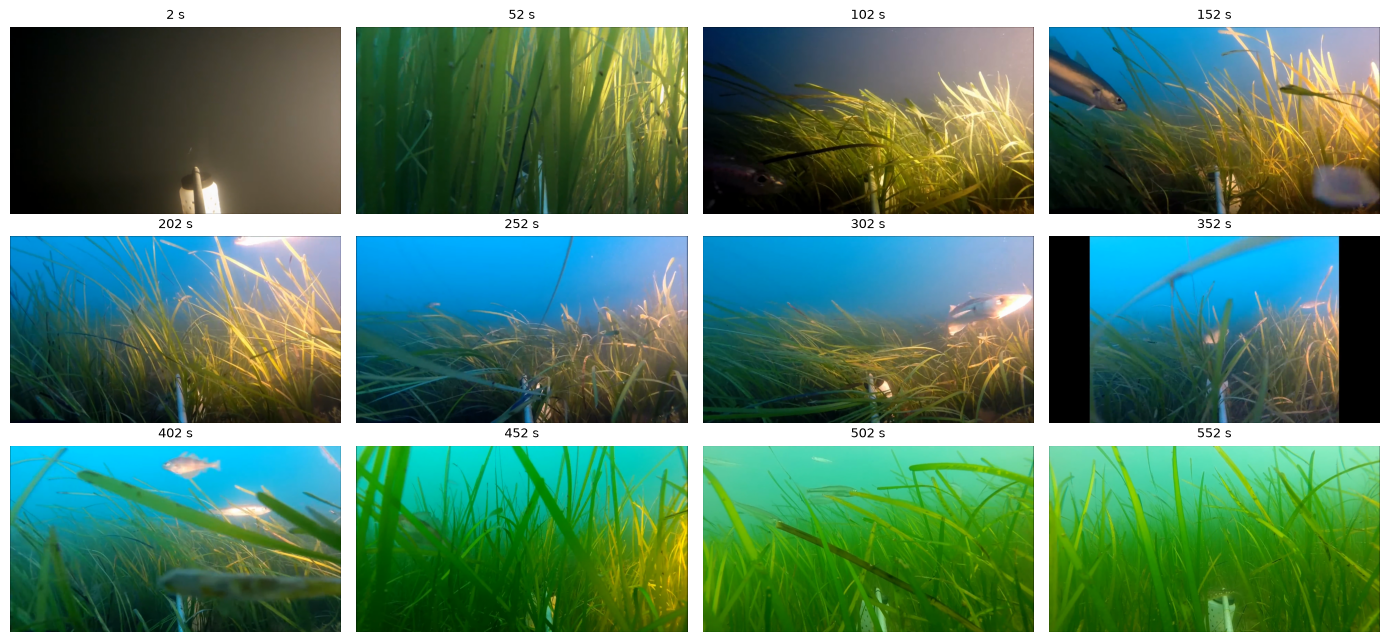

In [5]:
sample = sorted(frames, key=lambda f: second_of[f.name])[:: max(1, len(frames) // 12)][:12]
fig, axes = plt.subplots(3, 4, figsize=(14, 6.5))
for ax, path in zip(axes.flat, sample):
    ax.imshow(Image.open(path))
    ax.set_title(f"{second_of[path.name]:.0f} s", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Mark the fish

To score a detector, we need the right answer for each frame. **You are the right answer here.** Your clicks are called **ground truth**: the labels we choose to trust.

A box would take several seconds each. A dot takes one click, which matters when a frame has many fish. The cost is that we can check whether a detector found a fish, but not how tightly its box fits. The question that matters first is whether it found the fish at all.

**How to label:**
- **Click the middle of each fish.** Include partly hidden, blurry or far-away fish if you're confident it's a fish.
- **Click a dot again** to remove it, or press **Z** to undo the last one.
- **No fish in the frame?** Press **N**. A frame with no dots counts as "no fish", so this answer is just as useful.
- **Too dark or blurry to tell?** Press **U**. That's different from "no fish", and those frames are left out of the score.
- The bait stick, grass and floating bits aren't fish.

You won't see detector boxes while you label. If you could, you'd tend to agree with them, and the test would be checking the detector against itself.

Every answer saves straight away, so you can stop and come back. Tick **Brighten** on dark frames. Press **N** after clicking a frame. If a key does nothing, click the text above the picture and try again.

In [6]:
labeler = FishLabeler(frames, LABELS)
labeler

## 5. Run the detectors

Run this after labelling, or at the same time. The result doesn't depend on your labels, because each detector is scored afterwards.

A detector gives each box a **confidence**, a score from 0 to 1 for how sure it is. The **threshold** is the cut-off: boxes below it are thrown away. The app uses 0.3 today, and that number is a placeholder.

We keep every box above 0.05 once, so we can try any higher threshold later without running the model again. Results are saved, so running this cell twice is instant.

This uses `models.load_detector`, the same code the app runs, so we're testing what the app really does.

In [7]:
def run_detector(key):
    path = WORK / f"boxes-{key}.json"
    if path.exists():
        return json.loads(path.read_text())
    detector = models.load_detector(key)
    found = {}
    for frame in tqdm(frames, desc=key):
        boxes, confidence = detector.detect(Image.open(frame).convert("RGB"), LOW)
        order = np.argsort(-confidence)
        found[frame.name] = {"boxes": boxes[order].tolist(), "confidence": confidence[order].tolist()}
    path.write_text(json.dumps(found))
    return found


results = {key: run_detector(key) for key in DETECTORS}

W1105 21:18:58.365000 30451 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
/Users/allen/06_rbc_hubhacks_2026/.venv/lib/python3.14/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/Users/allen/06_rbc_hubhacks_2026/.venv/lib/python3.14/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/Users/allen/06_rbc_hubhacks_2026/.venv/lib/python3.14/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-11-05 21:18:58] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading 

cfd-nano:   0%|          | 0/120 [00:00<?, ?it/s]

[2026-11-05 21:18:58] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-11-05 21:19:05] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-05 21:19:05] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


cfd-small:   0%|          | 0/120 [00:00<?, ?it/s]

[2026-11-05 21:19:06] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-11-05 21:19:23] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-05 21:19:23] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


cfd-medium:   0%|          | 0/120 [00:00<?, ?it/s]

[2026-11-05 21:19:24] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


megalodon:   0%|          | 0/120 [00:00<?, ?it/s]

noaa-gray:   0%|          | 0/120 [00:00<?, ?it/s]

## 6. How we score

Each box, best first, can claim one dot that sits inside it. A claimed dot is a fish found.

- **Recall:** of the fish you marked, how many did the detector find? Missed fish lower it.
- **Precision:** of the boxes it drew, how many were on a fish? False alarms lower it.
- **F1:** one score that combines the two, and it's only high when both are.
- **False alarm frames:** of the frames you said were empty, how many got at least one box?

A lower threshold finds more fish and draws more false boxes. A higher one does the reverse. So a detector doesn't have one score. It has a curve, and the threshold picks a point on it.

In [8]:
answers = json.loads(LABELS.read_text()) if LABELS.exists() else {}
scored = [f.name for f in frames if answers.get(f.name, {}).get("status") == "labelled"]
unclear = sum(a["status"] == "unclear" for a in answers.values())
if len(scored) < MIN_LABELLED:
    raise RuntimeError(f"You've labelled {len(scored)} frames. Label at least {MIN_LABELLED} in section 4 first.")

points = {name: [(x * WIDTH, y * HEIGHT) for x, y in answers[name]["points"]] for name in scored}
fish = sum(len(p) for p in points.values())
empty = sum(not p for p in points.values())
print(f"{len(scored)} frames scored, {fish} fish, {empty} empty frames, {unclear} couldn't be judged")


def claimed(boxes, dots):
    open_dots, found = list(dots), 0
    for x1, y1, x2, y2 in boxes:
        for dot in open_dots:
            if x1 <= dot[0] <= x2 and y1 <= dot[1] <= y2:
                open_dots.remove(dot)
                found += 1
                break
    return found


def counts(key, threshold, names):
    # One row per frame: fish found, boxes drawn, fish marked.
    rows = []
    for name in names:
        result = results[key][name]
        boxes = [b for b, c in zip(result["boxes"], result["confidence"]) if c >= threshold]
        rows.append((claimed(boxes, points[name]), len(boxes), len(points[name])))
    return np.array(rows).reshape(-1, 3)


def score(rows):
    found, boxes, marked = rows.sum(0)
    recall = found / max(marked, 1)
    precision = found / max(boxes, 1)
    empty_frames = rows[:, 2] == 0
    return {
        "recall": recall,
        "precision": precision,
        "f1": 2 * recall * precision / max(recall + precision, 1e-9),
        "false_alarm_frames": (rows[empty_frames, 1] > 0).mean() if empty_frames.any() else float("nan"),
    }


def show(title, rows):
    print(title)
    print(f"{'detector':14s}{'threshold':>11s}{'recall':>8s}{'precision':>11s}{'F1':>6s}{'false alarm frames':>20s}")
    for key, threshold, result in rows:
        print(f"{key:14s}{threshold:11.2f}{result['recall']:8.2f}{result['precision']:11.2f}"
              f"{result['f1']:6.2f}{result['false_alarm_frames']:20.0%}")


show("At the app's current threshold", [
    (key, APP_THRESHOLD, score(counts(key, APP_THRESHOLD, scored))) for key in DETECTORS
])

RuntimeError: You've labelled 9 frames. Label at least 40 in section 4 first.

**Read the curves.** Top right is best: every fish found, and no false boxes. The large dot on each line is the app's threshold of 0.3.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for key in DETECTORS:
    curve = [score(counts(key, t, scored)) for t in THRESHOLDS]
    ax.plot([c["recall"] for c in curve], [c["precision"] for c in curve], color=COLORS[key], linewidth=2, label=key)
    point = score(counts(key, APP_THRESHOLD, scored))
    ax.plot(point["recall"], point["precision"], "o", color=COLORS[key], markersize=9,
            markeredgecolor="white", markeredgewidth=1.5)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall: share of marked fish found")
ax.set_ylabel("Precision: share of boxes on a fish")
ax.set_title("Each line sweeps the threshold from 0.05 to 0.95")
ax.grid(color="#e8e6e1", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## 7. Choose a threshold without fooling ourselves

If we pick the best threshold and then report the score on the same frames, the score flatters us. That's the same trap as leakage in `01`.

So we split the frames in two. We pick each detector's threshold on one half, then report its score on the other half. Your frames are already shuffled, so taking every other frame gives two fair halves.

The **interval** shows how much the score could move by luck. We redraw the test frames many times, a method called the **bootstrap**, and keep the middle 95% of the results.

Two limits to keep in mind: frames from one video are alike, so these intervals are too narrow. And with one clip, this says nothing about murkier water or other sites.

In [ ]:
choose, report = scored[::2], scored[1::2]
best, chosen = {}, []
for key in DETECTORS:
    trial = {t: score(counts(key, t, choose))["f1"] for t in THRESHOLDS}
    best[key] = float(max(trial, key=trial.get))
    chosen.append((key, best[key], score(counts(key, best[key], report))))
show(f"Threshold picked on {len(choose)} frames, scored on {len(report)} others", chosen)

rng = np.random.default_rng(SEED)
print(f"\n{'detector':14s}{'recall, 95% interval':>24s}{'precision, 95% interval':>26s}")
for key in tqdm(DETECTORS, desc="bootstrap"):
    rows = counts(key, best[key], report)
    draws = [score(rows[rng.integers(0, len(rows), len(rows))]) for _ in range(ROUNDS)]
    low_r, high_r = np.percentile([d["recall"] for d in draws], [2.5, 97.5])
    low_p, high_p = np.percentile([d["precision"] for d in draws], [2.5, 97.5])
    print(f"{key:14s}{low_r:15.2f} to {high_r:.2f}{low_p:17.2f} to {high_p:.2f}")

winner = max(chosen, key=lambda row: row[2]["f1"])[0]
print("\nHighest F1:", winner, "at threshold", best[winner])

## 8. Look at the mistakes

Numbers say how often a detector fails, and pictures show why. A **yellow ring** is a fish it missed. A **red box** is a false alarm. A **green box** found a fish.

Ask yourself: what do the misses have in common? Are they small, dim, or only flashes? Are the false alarms on the bait stick or the grass? Those answers tell us what to try next.

In [ ]:
def draw_result(ax, name, key, threshold):
    ax.imshow(Image.open(FRAMES / name))
    result = results[key][name]
    open_dots = list(points[name])
    for box, confidence in zip(result["boxes"], result["confidence"]):
        if confidence < threshold:
            continue
        x1, y1, x2, y2 = box
        dot = next((d for d in open_dots if x1 <= d[0] <= x2 and y1 <= d[1] <= y2), None)
        if dot:
            open_dots.remove(dot)
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2,
                                   edgecolor="#22c55e" if dot else "#ef4444"))
    for x, y in open_dots:
        ax.plot(x, y, "o", markersize=14, markerfacecolor="none", markeredgecolor="#facc15", markeredgewidth=2)
    ax.set_title(f"{second_of[name]:.0f} s", fontsize=9)
    ax.axis("off")


def errors(name):
    found, boxes, marked = counts(winner, best[winner], [name])[0]
    return (marked - found) + (boxes - found)


worst = sorted(scored, key=errors, reverse=True)[:12]
fig, axes = plt.subplots(3, 4, figsize=(15, 7))
for ax, name in zip(axes.flat, worst):
    draw_result(ax, name, winner, best[winner])
fig.suptitle(f"{winner} at threshold {best[winner]}: the 12 frames with the most mistakes")
plt.tight_layout()
plt.show()

## 9. What would a person still have to watch?

This is the question the product cares about. The app samples 2 frames each second, and any second with a box goes into the review queue, with a little time kept around it. We repeat that rule here on the whole clip.

- **Footage to watch:** the share of the clip in the queue. Lower saves more time.
- **Fish frames kept:** of your test frames with a fish, how many land in the queue. Lower means fish that may never be seen.

A detector can look good here while doing badly on recall: it only needs one box per second. It can also keep every second, and then it saves no time at all.

The real app also sends a random 10% of the quiet footage to audit, so a person could still catch some of what's lost. This cell runs the default detector and the winner over about 1,200 frames, and saves the results.

In [ ]:
def scan(key):
    path = WORK / f"scan-{key}.json"
    if path.exists():
        return json.loads(path.read_text())
    detector = models.load_detector(key)
    total = int(info["duration"] * config.DETECT_FPS)
    per_frame = []
    for buffer in tqdm(video.decode_frames(str(CLIP), WIDTH, HEIGHT, config.DETECT_FPS), total=total, desc=key):
        frame = np.frombuffer(buffer, dtype=np.uint8).reshape(HEIGHT, WIDTH, 3)
        _, confidence = detector.detect(Image.fromarray(frame[:, :, ::-1]), LOW)
        per_frame.append(confidence.tolist())
    path.write_text(json.dumps(per_frame))
    return per_frame


def queue(per_frame, threshold):
    # The same rule as build_segments in server/tidecount/worker.py.
    count = int(np.ceil(info["duration"]))
    active = np.zeros(count, dtype=bool)
    for index, confidence in enumerate(per_frame):
        if any(c >= threshold for c in confidence):
            active[min(count - 1, int(index / config.DETECT_FPS))] = True
    spans = []
    for second in np.flatnonzero(active):
        if spans and second - spans[-1][1] <= config.MERGE_GAP_S:
            spans[-1][1] = int(second)
        else:
            spans.append([int(second), int(second)])
    keep = np.zeros(count, dtype=bool)
    for start, end in spans:
        start, end = max(0, start - 1), min(count, end + 2)
        if end - start < config.MIN_SEGMENT_S:
            end = min(count, start + config.MIN_SEGMENT_S)
        keep[start:end] = True
    return keep


fish_frames = [name for name in scored if points[name]]
print(f"{'detector':14s}{'threshold':>11s}{'footage to watch':>18s}{'fish frames kept':>18s}")
for key in dict.fromkeys([config.DEFAULT_DETECTOR, winner]):
    per_frame = scan(key)
    for threshold in dict.fromkeys([APP_THRESHOLD, best[key]]):
        keep = queue(per_frame, threshold)
        kept = sum(keep[min(len(keep) - 1, int(second_of[name]))] for name in fish_frames)
        print(f"{key:14s}{threshold:11.2f}{keep.mean():18.0%}{kept / max(len(fish_frames), 1):18.0%}")

## 10. What to take away

Answer these from your own results before changing anything:

1. Which detector and threshold would you choose, and which number made you choose it?
2. Is 0.3 a good threshold for this footage?
3. What do the missed fish have in common?
4. How much watching does the queue save, and how many fish frames does it lose?
5. What's the cheapest thing to try next: a bigger model, a different threshold, more frames per second, or brightening the frames?

**What this doesn't tell us:** this is one clip, one labeller, and fish you could see in a still. A person watching the moving video would catch more, so true recall may be lower than your score says. A strong result here is only a start, and it needs the same test on a murkier clip.